# Experimento A/B en página de inicio

El objetivo de este proyecto es evaluar un **experimento A/B** realizado en una página de inicio (landing page) con versiónes **A y B** para apoyar una **decisión de negocio basada en datos**.

---

El archivo `landing_experiment.csv` contiene información de usuarios expuestos a dos versiones de la página de inicio (landing page) dentro del experimento A/B. Incluye región, dispositivo, fuente de tráfico, tipo de usuario, conversión y gasto.

El análisis sigue una lógica clara y progresiva:

1. 🔍 Explorar y validar los datos.

2. 💰 Comparar el **gasto promedio** por usuario entre la página A y B.

3. 🎯 Comparar la **tasa de conversión** entre la página A y B.

4. 🌐 Revisar **la relación entre la fuente de tráfico y la conversión**.

5. 👤 Revisar **la relación entre el tipo de usuario y la conversión**.

6. 📈 **Visualización de los resultados**

Se aplican **puebas estadísticas apropiados** para comparar las páginas y **recomendar qué versión es mejor**, justificando la decisión con datos.

## 🧩 Paso 1: Cargar y validar los datos

### 1.1 Carga de datos y vista rápida

In [ ]:
# importar librerías
import pandas as pd


In [ ]:
# cargar archivo
df = pd.read_csv('/datasets/landing_experiment.csv')

**Vista previa e información general del conjunto de datos**

In [ ]:
# mostrar las primeras 5 filas
df.head(5)

,user_id,date,landing,region,dispositivo,traffic_source,user_type,converted,gasto
0,26f3052e-8500-44ea-8fff-06de65258abb,2026-01-01,A,Norte,Mobile,Email,Recurrente,1,38.08
1,92378c09-4bbf-40c7-945e-82b84f392d22,2026-01-23,A,Occidente,Mobile,Organic,Nuevo,0,0.00
2,a4397360-40e5-45d6-a7ff-dcb4da2c9a1f,2026-01-01,B,Centro,Mobile,Organic,Nuevo,0,0.00
3,7ca3a26f-1e6c-44aa-9b09-b8cb01112956,2026-01-22,A,Centro,Mobile,Ads,Nuevo,0,0.00
4,8dc9593b-5b9c-479d-848b-a99493920419,2026-01-16,A,Sur,Mobile,Organic,Nuevo,0,0.00


In [ ]:
# información general
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 40000 entries, 0 to 39999
Data columns (total 9 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   user_id         40000 non-null  object 
 1   date            40000 non-null  object 
 2   landing         40000 non-null  object 
 3   region          40000 non-null  object 
 4   dispositivo     40000 non-null  object 
 5   traffic_source  40000 non-null  object 
 6   user_type       40000 non-null  object 
 7   converted       40000 non-null  int64  
 8   gasto           40000 non-null  float64
dtypes: float64(1), int64(1), object(7)
memory usage: 2.7+ MB


✍️ **Comentario**:
 Se identifica que no se presentan valores nulos, ni faltantes, la columna `date` es tipo object, así que debe cambiarse a tipo `datetime`.

**Descripción del conjunto de datos**

El dataset contiene las siguientes columnas:

- `user_id` — Identificador único del usuario
- `date` — Fecha en la que el usuario fue expuesto a la página
- `landing` — Versión de la página mostrada al usuario
- `region` — Región geográfica del usuario
- `dispositivo` — Tipo de dispositivo utilizado por el usuario
- `traffic_source` — Canal por el que llegó el usuario
- `user_type` — Tipo de usuario según historial previo
- `converted` — Indica si el usuario realizó una conversión
- `gasto` — Monto gastado por el usuario (0 si no convirtió)

### 1.2 Análisis exploratorio y revisión de calidad de datos

Se identifican las variables clave del experimento A/B y se valida que estén bien definidas, completas y que sean consistentes.


 **Variable `user_id`**  
 Verificar usuarios únicos

In [ ]:
print('cantidad de valores unicos:',df['user_id'].nunique())
print('cantidad de valores duplicados:',df['user_id'].duplicated().sum())

cantidad de valores unicos: 40000
cantidad de valores duplicados: 0


 **Variable `date`**  
Explorar rango de fechas

In [ ]:
# Resumen estadístico
df["date"].describe()

count          40000
unique            28
top       2026-01-24
freq            1512
Name: date, dtype: object

In [ ]:
# Identificar rango temporal del experimento
print("Fecha mínima:", df["date"].min())
print("Fecha máxima:", df["date"].max())

Fecha mínima: 2026-01-01
Fecha máxima: 2026-01-28


**Variable `gasto` (numérica)**

In [ ]:
# Resumen estadístico
df['gasto'].describe()

count    40000.000000
mean         9.325554
std         25.667986
min          0.000000
25%          0.000000
50%          0.000000
75%          0.000000
max        303.680000
Name: gasto, dtype: float64

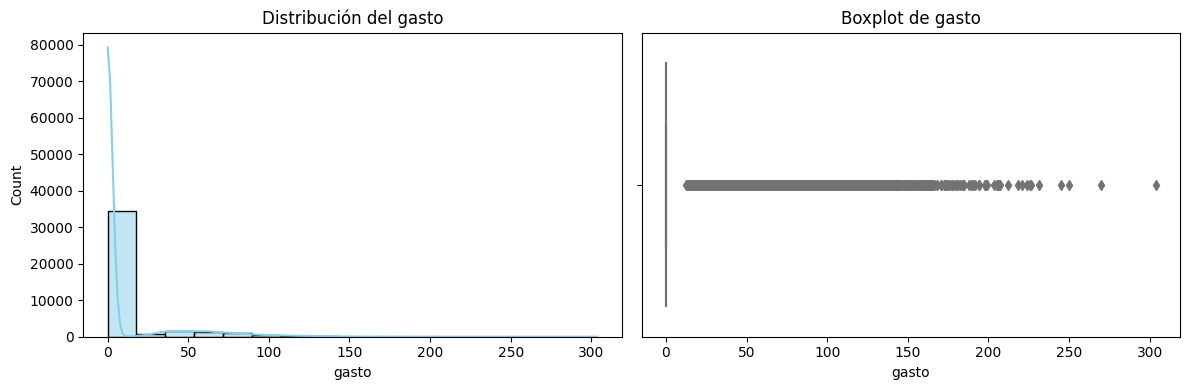

In [ ]:
import seaborn as sns
import matplotlib.pyplot as plt

fig, axes = plt.subplots(1,2,figsize =  (12,4))
sns.histplot(data = df, x = 'gasto', kde = True, ax = axes[0], color ='skyblue')
axes[0].set_title('Distribución del gasto')

sns.boxplot(data = df, x = 'gasto', ax = axes[1],  color = 'lightgreen')
axes[1].set_title('Boxplot de gasto')

plt.tight_layout()
plt.show()

In [ ]:
# Resumen estadístico de usuarios que se convirtieron
df['converted'].describe()

count    40000.00000
mean         0.14265
std          0.34972
min          0.00000
25%          0.00000
50%          0.00000
75%          0.00000
max          1.00000
Name: converted, dtype: float64

 **Variables categóricas**  
 Verificar categorías esperadas del experimento ( A y B).

In [ ]:
# Explorar variables categóricas y cómo se distribuyen
columnas = ['landing','region','dispositivo','traffic_source','user_type','converted']
for col in columnas:
    print(f"\nConteo de categorías: {col}")
    conteo = df[col].value_counts()
    porcentaje = df[col].value_counts(normalize = True)*100
    resumen = pd.DataFrame(
        {'conteo': conteo, 'porcentaje %': porcentaje.round(2)}
    )

    print(resumen)
    print()



Conteo de categorías: landing
   conteo  porcentaje %
B   20018         50.04
A   19982         49.96


Conteo de categorías: region
           conteo  porcentaje %
Norte       11166         27.92
Centro       9613         24.03
Sur          8039         20.10
Occidente    6398         16.00
Oriente      4784         11.96


Conteo de categorías: dispositivo
         conteo  porcentaje %
Mobile    24829         62.07
Desktop   15171         37.93


Conteo de categorías: traffic_source
          conteo  porcentaje %
Organic    17987         44.97
Ads        11935         29.84
Email       6123         15.31
Referral    3955          9.89


Conteo de categorías: user_type
            conteo  porcentaje %
Nuevo        26033         65.08
Recurrente   13967         34.92


Conteo de categorías: converted
   conteo  porcentaje %
0   34294         85.74
1    5706         14.26



✍️ **Comentario**: 

En la variable `user_id` se encuentran *40000* usuarios unicos.

En la variable `date` se observa que los datos son obtenidos del mes de enero de 2026 durante 28 días y que el día 24 es el que presenta mayor frecuencia de información con 1512 datos.

En la variable `gasto` no hay valores extraños o errados, solo se detecta que el 75% de los datos con `0`, así que esto muestra una distribución de los datos muy sesgada dando lugar a que valores mayores a `0` se muestren como atipicos.

En la variable `converted` se observa que solo tiene valores de `0` o `1`, siendo el 85% y el 14% de los datos respectivamente.

En las variables categoricas no se encontraron sentinels o datos extraños y la variable `landing`, entre las paginas A y B mantienen similar cantidad de datos.



## 💰 Paso 2: Comparar el gasto promedio por usuario (página A vs B)

Se evalua si existen diferencias estadísticamente significativas en el gasto promedio de los **usuarios que se convirtieron en clientes** entre la página A y la página B, para identificar qué versión genera **mayor valor económico** para el negocio.


In [ ]:
# Gasto por versión
gasto_A = df[(df['converted'] == 1) & (df['landing'] == 'A')]['gasto']#completa el código
gasto_B = df[(df['converted'] == 1) & (df['landing'] == 'B')]['gasto']#completa el código

# Verificar cantidad de datos que tiene cada grupo
len(gasto_A), len(gasto_B)

(2512, 3194)

In [ ]:
# Comparación de gasto promedio por página
data = pd.DataFrame({'Págian':['A','B'],
                   'Gasto promedio':[gasto_A.mean(),gasto_B.mean()] })
data

,Págian,Gasto promedio
0,A,61.086572
1,B,68.745360


## Prueba de Levene( test de varianzas)

**Hipótesis nula Ho:** Las varianza de `gasto_A` es ingual a la varianza de `gasto_B`.

**Hipótesis alterna H1:** Las varianza de `gasto_A` es diferente a la varianza de `gasto_B`

In [ ]:
# comprovación de hipótesis
from scipy.stats import levene

l_stat, p_value_var = levene(gasto_A,gasto_B)

print(f'Estadístico Levene: {l_stat}')
print(f'valor p: {p_value_var}')


print()
alpha = 0.05

if p_value_var < alpha:
    print('Se rechaza la hipótesis nula, hay diferencias entre varianzas de los grupos')
else:
    print('No se rechaza la hipótesis nula, hay igualdad entre varianzas de los grupos')


Estadístico Levene: 29.17646453202917
valor p: 6.875301988016449e-08

Se rechaza la hipótesis nula, hay diferencias entre varianzas de los grupos


### Prueba ...

**Hipótesis:**
- **Hipótesis nula (H₀):** No hay diferencias significativas en el gasto promedio de los usuarios entre la página  A y B
- **Hipótesis alternativa (H₁):** Hay diferencias significativas en el gasto promedio de los usuarios entre las página A y B 

In [ ]:
# Aplicar prueba t de student
from scipy.stats import ttest_ind

t_stat, p_value = ttest_ind(gasto_A,gasto_B, equal_var = False)

# Visualizar resultados
print(f"Estadístico : {t_stat}")
print(f"Valor p: {p_value}")

print()
alpha = 0.05

if p_value < alpha:
    print('Se rechaza la hipótesis nula y hay diferencias significativas en el gasto promedio')
else:
    print('No se rechaza la hipótesis nula, y no se presentan diferencias significativas en el gasto promedio')

Estadístico : -9.48101092267275
Valor p: 3.627602231521493e-21

Se rechaza la hipótesis nula y hay diferencias significativas en el gasto promedio


### 📝 Conclusión e interpretación

**Decisión:**  
Con un valor p = 3.627602231521493e-21 < 0.05, se rechaza la hipótesis nula; hay diferencias significativas en el gasto promedio entre las páginas A y B

**Interpretación de negocio:**  
Se concluye que hay una diferencia estadísticamente significativa en el gasto promedio de los usuarios que usaron la página A respecto a los usuarios que usaron la página B.

Se observa que la página B obtuvo un gasto promedio de 68.7, superior al gasto promedio de la página A con un 61.08 


---


## 📈 Paso 3: Comparar la tasa de conversión entre la página A y B

Se evalua si existen diferencias estadísticamente significativas en la **tasa de conversión** entre la página A y B, con el fin de identificar qué versión genera **mayor número de usuarios convertidos**.

### Prueba ...

**Hipótesis:**
- **Hipótesis nula (H₀):** La tasa de conversión de la página A es igual a la página B.
- **Hipótesis alternativa (H₁):** La tasa de conversión es diferente entre las páginas.

In [ ]:
# Número de usuarios convertidos por página
from statsmodels.stats.proportion import proportions_ztest

Conversion = df.groupby('landing')['converted'].sum()
Exitos = [Conversion['A'], Conversion['B']]
# Total de usuarios por página

Total = df.groupby('landing')['converted'].count()
Observaciones = [Total['A'], Total['B']]

print("Usuarios convertidos por página:\n")
print(f'Pagina A: {Exitos[0]}')
print(f'Pagina B: {Exitos[1]}')

print("\nTotal de usuarios por página:\n")
print(f'Pagina A: {Observaciones[0]}')
print(f'Pagina B: {Observaciones[1]}')

Usuarios convertidos por página:

Pagina A: 2512
Pagina B: 3194

Total de usuarios por página:

Pagina A: 19982
Pagina B: 20018


In [ ]:
# Aplicar prueba
z_stat, p_value_z = proportions_ztest(Exitos, Observaciones)

# Visualizar resultados
print(f"Estadístico : {z_stat}")
print(f"Valor p: {p_value_z}")
print()

alpha = 0.05

if p_value_z < alpha:
    print('Se rechaza la hipótesis nula, se presentan diferencias entre tasas de conversión de cada página')
else:
    print('No se rechaza la hipótesis nula, no se presentan diferencias entre las tasas de conversión de cada página')

    

Estadístico : -9.677362674655983
Valor p: 3.7629765627523803e-22

Se rechaza la hipótesis nula, se presentan diferencias entre tasas de conversión de cada página


In [ ]:
# verificando la proporción de converción por página

tasa_A = (Exitos[0]/Observaciones[0])*100
tasa_B = (Exitos[1]/Observaciones[1])*100

print(f'Tasa de conversión de la página A: {tasa_A.round(2)}')
print(f'Tasa de conversión de la página B: {tasa_B.round(2)}')

Tasa de conversión de la página A: 12.57
Tasa de conversión de la página B: 15.96


### 📝 Conclusión e interpretación

**Decisión:**  
Al realizar la prueba Z de proporciones, el valor p = 3.7629765627523803e-22 fue muy menor a 0.05 lo cual indica que se debe rechazar la hipótesis nula de igualdad en tasas de conversión entre la página A y B.

**Interpretación de negocio:**  

Hay una diferencia significativa ya que la página A convirtio al 12.57% de los usuarios y la página B convirtio al 15.96% de los usuarios, dando así una diferencia de alrededor del 3% entre las páginas.

En terminos de negocio hay que evaluar que tan positivo en ganancias representa una brecha del 3%.

## 🔗 Paso 4: Revisar la relación entre la fuente de tráfico y la conversión

Se analiza si existe una **asociación estadísticamente significativa** entre la **fuente de tráfico** (`traffic_source`) y la **conversión** (`converted`), para identificar qué canales generan más conversiones.

### Prueba ...

**Hipótesis:**
- **Hipótesis nula (H₀):** No hay una relación entre las variables `traffic_source` y `converted`, ambas son independientes.
- **Hipótesis alternativa (H₁):** Existe una relación entre las variables `traffic_source` y `converted`, ambas son dependientes.

In [ ]:
from scipy.stats import chi2_contingency

In [ ]:
# Aplicar prueba
Tabla = pd.crosstab(df['traffic_source'],df['converted'])
Tabla

converted,0,1
traffic_source,,
Ads,10176,1759
Email,5205,918
Organic,15507,2480
Referral,3406,549


In [ ]:

chi2_stats, value_p_chi, dof, expected = chi2_contingency(Tabla)

print(f'Estadistico: {chi2_stats}')
print(f'Valor p: {value_p_chi}')
print(f'Grados de libertad: {dof} \n')

expected_df = pd.DataFrame(expected, index = Tabla.index, columns = Tabla.columns)
print('Valores esperados')
print(expected_df.round(0))



Estadistico: 8.662108841397938
Valor p: 0.0341375947833914
Grados de libertad: 3 

Valores esperados
converted             0       1
traffic_source                 
Ads             10232.0  1703.0
Email            5250.0   873.0
Organic         15421.0  2566.0
Referral         3391.0   564.0


In [ ]:

if value_p_chi < 0.05:
    print('Se rechaza la hipótesis nula, hay una relación entre las variables')
else:
    print('No se rechaza la hipótesis nula, no se presenta una relación entre variables')


Se rechaza la hipótesis nula, hay una relación entre las variables


### 📝 Conclusión e interpretación

**Decisión:**  
 on un valor p = 0.0341 < alpha = 0.05, se rechaza la hipótesis nula. Esto indica que existe evidencia estadística de una relación de dependencia entre `traffic_source` y la `converted`. 

**Interpretación de negocio:**  
Debido a que hay una asociación significativa entre la fuente de tráfico y la conversión, el negocio debe evaluar la magnitud de diferencia de la tasa de conversión entre fuentes de tráfico, para justificar inversiones operativas

<div class="alert alert-block alert-success">
<b>Comentario del revisor. (Iteración 1)</b> <a class="tocSkip"></a>

✅ Chi-cuadrado correcto.
</div>

## 👤 Paso 5: Revisar la relación entre el tipo de usuario y la conversión

Se analiza si existe una **asociación estadísticamente significativa** entre el **tipo de usuario** (`user_type`) y la **conversión** (`converted`), entendiendo que un usuario recurrente puede haber visitado antes sin necesariamente convertirse en cliente en esta ocasión.

El objetivo es identificar qué perfiles muestran mayor probabilidad de conversión dentro del contexto analizado.

### Prueba ...

**Hipótesis:**
- **Hipótesis nula (H₀):** No hay una asociación estadísticamente significativa entre `user_type` y `converted`.
- **Hipótesis alternativa (H₁):** Hay una asociación estadísticamente significativa entre `user_type` y `converted`.

In [ ]:
Tabla_2 = pd.crosstab(df['user_type'], df['converted'])
Tabla_2

converted,0,1
user_type,,
Nuevo,22295,3738
Recurrente,11999,1968


In [ ]:
# Aplicar prueba

chi2_stats_2, value_p_chi_2, dof_2, expected_2 = chi2_contingency(Tabla_2)

print(f'Estadistico: {chi2_stats_2}')
print(f'Valor p: {value_p_chi_2}')
print(f'Grados de libertad: {dof_2} \n')

expected_df = pd.DataFrame(expected_2, index = Tabla_2.index, columns = Tabla_2.columns)
print('Valores esperados')
print(expected_df.round(0))

Estadistico: 0.5134849494478645
Valor p: 0.4736341272301974
Grados de libertad: 1 

Valores esperados
converted         0       1
user_type                  
Nuevo       22319.0  3714.0
Recurrente  11975.0  1992.0


In [ ]:
if value_p_chi_2 < 0.05:
    print('Se rechaza la hipótesis nula, hay una relación entre las variables')
else:
    print('No se rechaza la hipótesis nula, no se presenta una relación entre variables')

No se rechaza la hipótesis nula, no se presenta una relación entre variables


### 📝 Conclusión e interpretación

**Decisión:**  
No se rechaza la hipotesis nula con un valor p = 0.47 > 0.05, no hay asociación estadísticamente significativa entre `user_type` y `converted`.

**Interpretación de negocio:**  
Este resultado sugiere que, bajo las condiciones actuales de la plataforma, el tipo de usuario no actúa como un factor diferenciador en la tasa de conversión. Para el negocio, más que descartar esfuerzos en este segmento, abre la hipótesis de si es necesario diseñar estrategias o embudos específicos (por ejemplo, programas de fidelización) para potenciar la conversión en usuarios recurrentes.

## 📊 Paso 6: Visualizar los resultados de variables categóricas

Se explora visualmente la relación entre variables categóricas (`traffic_source` y `user_type`) y la conversión, mostrando para cada categoría:
- la cantidad absoluta de usuarios que convirtieron y no convirtieron,
- la proporción de usuarios que convirtieron y no convirtieron.

Esto permite analizar tanto el impacto en volumen como la efectividad relativa de cada categoría y reforzar los resultados obtenidos en las pruebas estadísticas.

### Relación entre la fuente de tráfico y la conversión

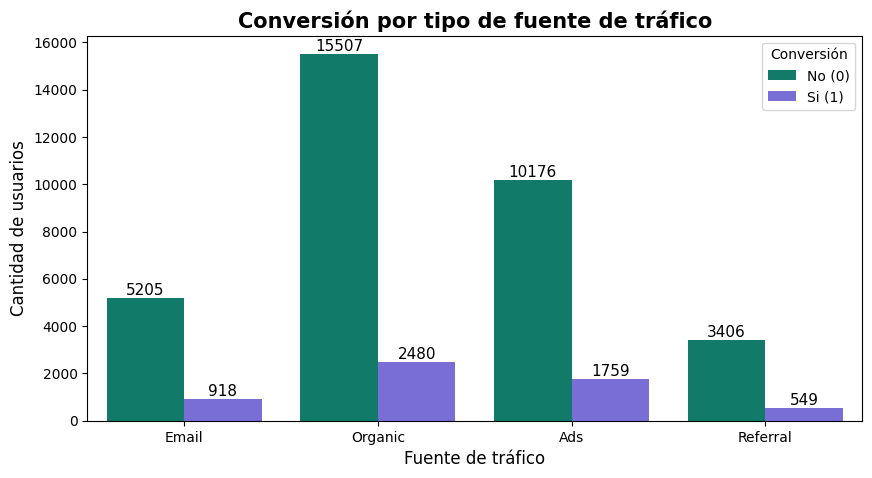

In [ ]:
plt.figure(figsize=(10,5))
ax = sns.countplot(data = df, 
                   x = 'traffic_source', 
                   hue = 'converted',
                   palette = ['#008B74','#6C5CE7'])
for bar in ax.patches:
    height = bar.get_height()
    ax.text(x = bar.get_x() + bar.get_width()/2,
           y = height,
           s = height,
           ha = 'center',
           va = 'bottom',
           fontsize = 11)

plt.title('Conversión por tipo de fuente de tráfico', fontsize = 15,fontweight='bold')
plt.xlabel('Fuente de tráfico', fontsize = 12)
plt.ylabel('Cantidad de usuarios', fontsize = 12)
plt.legend(title = 'Conversión', labels = ['No (0)', 'Si (1)'])
plt.show()

✍️ **Comentario**:


Observando el gráfico de barras se observa que `Organic` y `Ads` dominan en volumen de usuarios
`Email` y `Referral` presentan un volumen inferior.
Para el negocio sería interesante evaluar que puede mejorar en los emails como en la fuente de tráfico de referencias.


In [ ]:
tabla_pro = pd.crosstab(df['traffic_source'],df['converted'], normalize = 'index')*100
tabla_pro

converted,0,1
traffic_source,,
Ads,85.261835,14.738165
Email,85.007349,14.992651
Organic,86.212264,13.787736
Referral,86.118837,13.881163


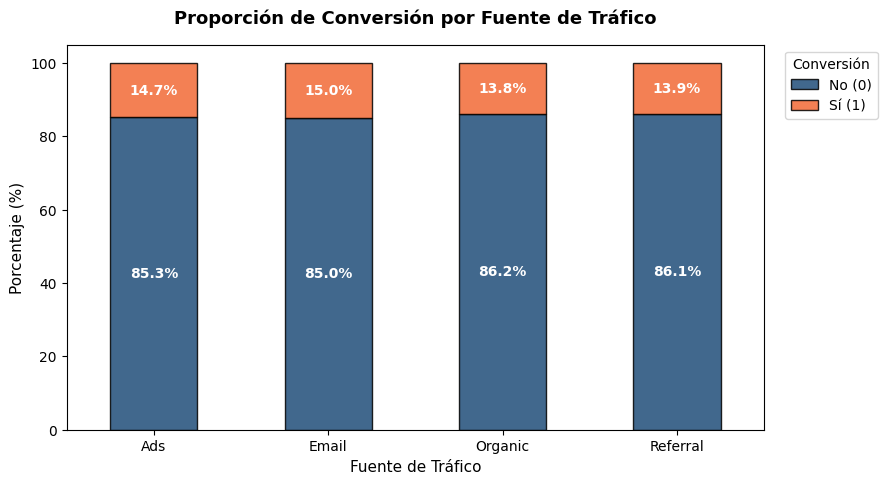

In [ ]:

ax = tabla_pro.plot(
    kind='bar',
    stacked=True,
    figsize=(9, 5),
    color=['#1F4E79', '#F26A36'],
    edgecolor='black',
    alpha=0.85)

for p in ax.patches:
  width, height = p.get_width(), p.get_height()
  if height > 0:  # Mostrar solo si la proporción es mayor a 0
    x, y = p.get_xy()
    ax.text(
        x + width / 2,
        y + height / 2,
        f'{height:.1f}%',
        ha='center',
        va='center',
        color='white',
        fontweight='bold',
        fontsize=10,
    )

plt.title(
    'Proporción de Conversión por Fuente de Tráfico',
    fontsize=13,
    fontweight='bold',
    pad=15,
)
plt.xlabel('Fuente de Tráfico', fontsize=11)
plt.ylabel('Porcentaje (%)', fontsize=11)
plt.xticks(rotation=0)
plt.legend(
    title='Conversión',
    labels=['No (0)', 'Sí (1)'],
    bbox_to_anchor=(1.02, 1),
    loc='upper left',
)

plt.show()


✍️ **Comentario**:


Las fuentes de tráfico tienen una tasa de conversión similar, no hay una significativamente destacable; el segmento `Email` se muestran como los mas eficientes al tener una tasa de conversión de 15% respecto al volumen generado de usuarios.

Para el negocio sería adecuado evaluar escaldas de captación de usuarios en los segmentos mas eficientes en conversión por volumen.


### Relación entre el tipo de usuario y la conversión

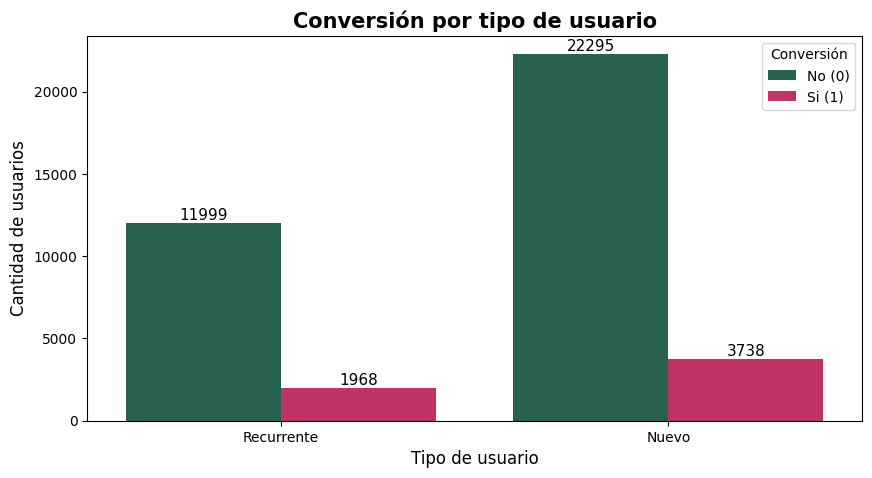

In [ ]:

plt.figure(figsize=(10,5))
ax = sns.countplot(data = df, 
                   x = 'user_type', 
                   hue = 'converted',
                   palette = ['#1E6B52','#D81B60'])
for bar in ax.patches:
    height = bar.get_height()
    ax.text(x = bar.get_x() + bar.get_width()/2,
           y = height,
           s = height,
           ha = 'center',
           va = 'bottom',
           fontsize = 11)

plt.title('Conversión por tipo de usuario', fontsize = 15,fontweight='bold')
plt.xlabel('Tipo de usuario', fontsize = 12)
plt.ylabel('Cantidad de usuarios', fontsize = 12)
plt.legend(title = 'Conversión', labels = ['No (0)', 'Si (1)'])
plt.show()


✍️ **Comentario**:

Como se muestra en el gráfico los usuarios nuevos representan mas de la mitad del volumen, la página tiene una gran capacidad de captar usuarios nuevos y hacer que en valores adsolutos estos usuarios nuevos conviertan al mismo ritmo que los usuarios recurrentes.
Aqui se presenta una oportunidad de convertir a los usuarios nuevos en recurrentes mediante programas de fidelidad.

In [ ]:

Tabla_prop = pd.crosstab(df['user_type'],df['converted'], normalize = 'index')*100
Tabla_prop


converted,0,1
user_type,,
Nuevo,85.641301,14.358699
Recurrente,85.909644,14.090356


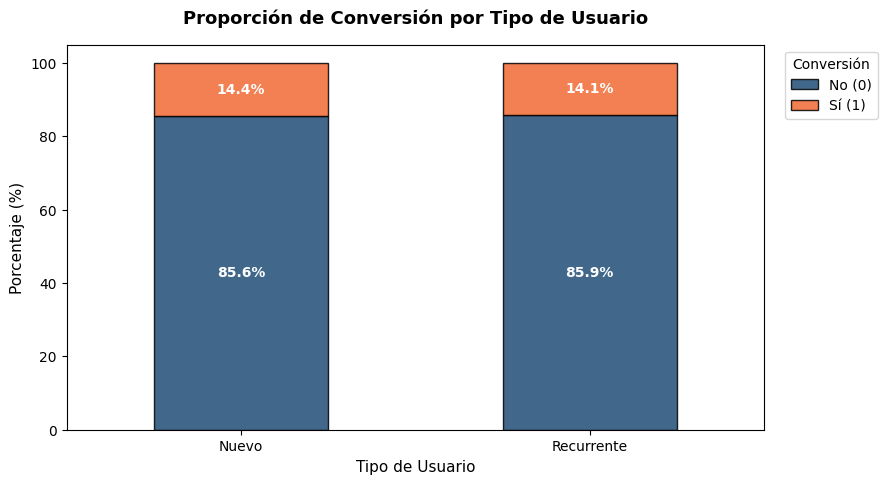

In [ ]:

ax = Tabla_prop.plot(
    kind='bar',
    stacked=True,
    figsize=(9, 5),
    color=['#1F4E77', '#F26A35'],
    edgecolor='black',
    alpha=0.85)

for p in ax.patches:
  width, height = p.get_width(), p.get_height()
  if height > 0:  # Mostrar solo si la proporción es mayor a 0
    x, y = p.get_xy()
    ax.text(
        x + width / 2,
        y + height / 2,
        f'{height:.1f}%',
        ha='center',
        va='center',
        color='white',
        fontweight='bold',
        fontsize=10,
    )

plt.title(
    'Proporción de Conversión por Tipo de Usuario',
    fontsize=13,
    fontweight='bold',
    pad=15,
)
plt.xlabel('Tipo de Usuario', fontsize=11)
plt.ylabel('Porcentaje (%)', fontsize=11)
plt.xticks(rotation=0)
plt.legend(
    title='Conversión',
    labels=['No (0)', 'Sí (1)'],
    bbox_to_anchor=(1.02, 1),
    loc='upper left',
)

plt.show()


✍️ **Comentario**: 

De acuerdo a la gráfica de barras apiladas, no hay una diferencia destacable en la tasa de 14% de conversión por tipo de usuario.
La tasa de conversión para usuarios nuevos del 14% refleja efectividad en el embudo de adquisición inicial.
Se presenta una oportunidad de mejora en el segmento de usuarios recurrentes, ya que se espera que estos tengan una tasa mayor al ser usuarios que ya conocen la marca.

## 7.3. Relación entre el tipo de página y la conversión

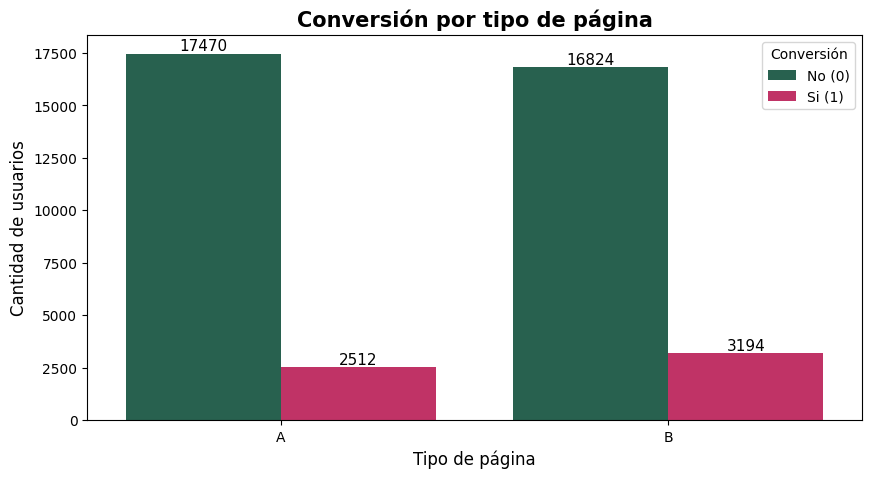

In [ ]:
plt.figure(figsize=(10,5))
ax = sns.countplot(data = df, 
                   x = 'landing', 
                   hue = 'converted',
                   palette = ['#1E6B52','#D81B60'])
for bar in ax.patches:
    height = bar.get_height()
    ax.text(x = bar.get_x() + bar.get_width()/2,
           y = height,
           s = height,
           ha = 'center',
           va = 'bottom',
           fontsize = 11)

plt.title('Conversión por tipo de página', fontsize = 15,fontweight='bold')
plt.xlabel('Tipo de página', fontsize = 12)
plt.ylabel('Cantidad de usuarios', fontsize = 12)
plt.legend(title = 'Conversión', labels = ['No (0)', 'Si (1)'])
plt.show()

In [ ]:
Tabla_prop = pd.crosstab(df['landing'],df['converted'], normalize = 'index')*100
Tabla_prop

converted,0,1
landing,,
A,87.428686,12.571314
B,84.044360,15.955640


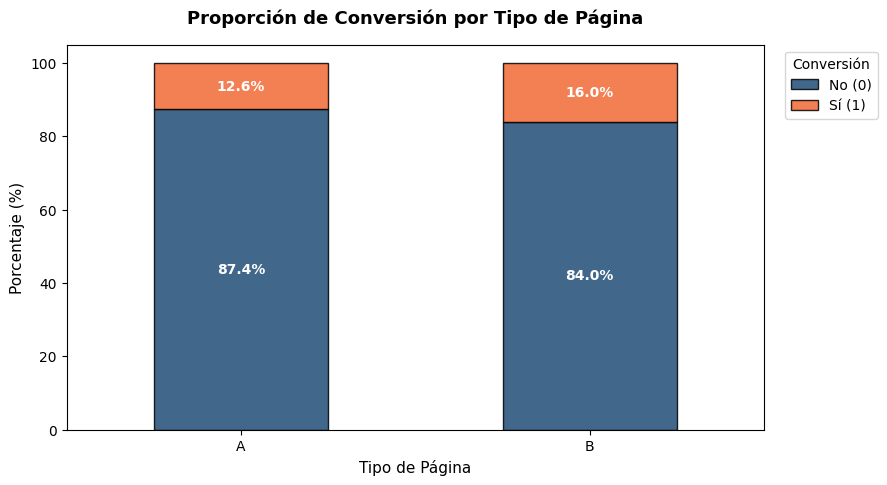

In [ ]:
ax = Tabla_prop.plot(
    kind='bar',
    stacked=True,
    figsize=(9, 5),
    color=['#1F4E77', '#F26A35'],
    edgecolor='black',
    alpha=0.85)

for p in ax.patches:
  width, height = p.get_width(), p.get_height()
  if height > 0:  # Mostrar solo si la proporción es mayor a 0
    x, y = p.get_xy()
    ax.text(
        x + width / 2,
        y + height / 2,
        f'{height:.1f}%',
        ha='center',
        va='center',
        color='white',
        fontweight='bold',
        fontsize=10,
    )

plt.title(
    'Proporción de Conversión por Tipo de Página',
    fontsize=13,
    fontweight='bold',
    pad=15,
)
plt.xlabel('Tipo de Página', fontsize=11)
plt.ylabel('Porcentaje (%)', fontsize=11)
plt.xticks(rotation=0)
plt.legend(
    title='Conversión',
    labels=['No (0)', 'Sí (1)'],
    bbox_to_anchor=(1.02, 1),
    loc='upper left',
)

plt.show()

✍️ **Comentario**:

De acuerdo a la gráfica de barras agrupadas, la página B obtuvo más cantidad de conversión en número de usuarios respecto a la página A y así mismo se ve su eficiencia en porcentajes, con valor de 16% respecto a un 12,6% de la página A.

## 🧩 Paso 7. Insight Ejecutivo para Stakeholders

Se traducen los hallazgos del análisis del experimento A/B en conclusiones accionables para el negocio, enfocadas en **versión de página, conversión, gasto promedio, canales de tráfico y tipo de usuario**.

**Preguntas a responder:**  
- ¿Qué página genera mayor conversión y gasto promedio?  
- ¿Qué canales de tráfico son más efectivos para generar conversiones?  
- ¿Existen diferencias significativas según el tipo de usuario?  
- ¿Qué recomendaciones se pueden tomar para optimizar la estrategia de marketing?


---

### 🌟 Insight Ejecutivo basado en el Experimento A/B

#### 🔍 **Comparación de página (A vs B)**  

**Gasto promedio por usuario que convirtió:**
- 
La prueba de hipótesis concluye que hay una diferencia significativa entre el gasto promedio de las páginas. 
- La página A obtuvo un gasto promedio de 61.09 y la página B un 68.7

- **Interpretación:** La página B con un gasto promedio superior a la página A, y la prueba de hipótesis con p < 0.05 confirma que la diferencia estadística entre las páginas no es producto del azar, sino un comportamiento de compra de la página B superior a la página A.

<br>

**Tasa de conversión:** 
- La prueba de hipótesis con p < 0.05 concluye que hay una diferencia significativa entre las tasas de conversión de ambas páginas.
- La página B obtuvo una tasa de conversión de 15.96% versus una tasa de conversión de la página A de 12.57%. 
- **Interpretación:** La página B es claramente superior a la página A; la prueba indica que este hecho no es producto del azar, sino un rendimiento mejor y replicable.

---

#### 📊 **Segmentación por fuente de tráfico**
- Con un valor p = 0.034 < 0.05 se halla una relación significativa entre la fuente de tráfico y la conversión de usuarios.
- Las tasas de conversión entre fuentes de tráfico fueron muy similares, entre 13% y 15% de conversión.
- **Interpretación:** La tasa de conversión por fuente de tráfico arrojó que el segmento de Email es el más eficiente con un 15% de conversión; es la fuente de tráfico con la mayor probabilidad individual de lograr que un usuario convierta.
- En cuanto a magnitud e impacto global, Organic y Ads sostienen la mayor parte del flujo de conversiones del negocio por el número de usuarios que atrae.
 
 ---

#### 📊 **Segmentación por tipo de usuario**
- No se encontró evidencia de diferencias estadísticamente significativas por tipo de usuario.
- Usuarios Nuevos: Tasa de conversión del 14.36% (3,738 convertidos de 26,033 usuarios).
- Usuarios Recurrentes: Tasa de conversión del 14.09% (1,968 convertidos de 13,967 usuarios).
- **Interpretación:** La plataforma demuestra una capacidad sólida para convertir a usuarios primerisos (14.36%) al mismo ritmo que a los usuarios que ya conocen la marca.

---
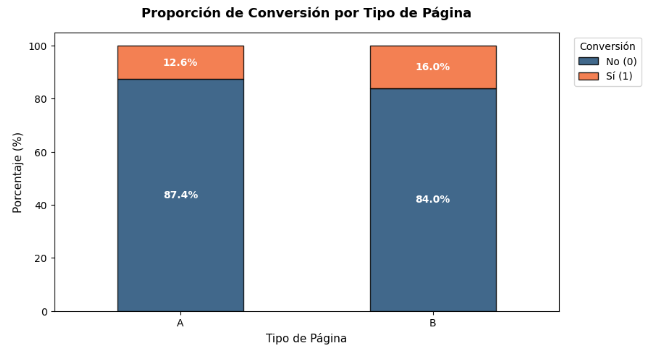
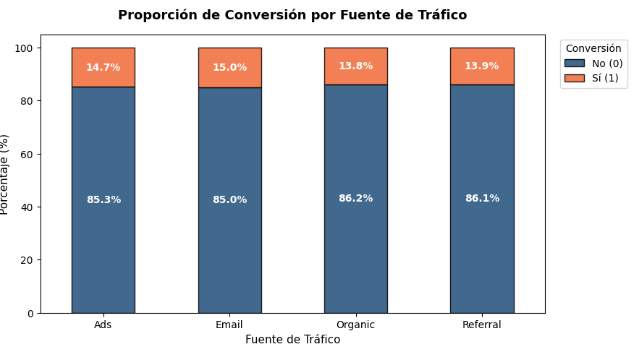
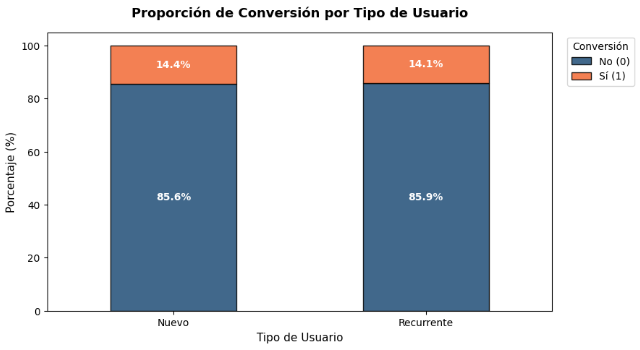

---

#### 💡 **Recomendaciones de negocio:** 
- Se recomienda implementar de forma definitiva la página B como la versión principal de la landing page, ya que maximiza tanto la captación de usuarios convertidos como los ingresos promedio generados.
-  Dado que todas las fuentes se mueven en un rango muy estrecho (13% a 15%), la decisión de inversión no debe basarse únicamente en el porcentaje de conversión, sino en evaluar el costo de adquisición de cliente por fuente de tráfico
- Se recomienda mejorar o dar incentivos específicos para hacer que los usuarios recurrentes generen una mayor conversión. 